> **언어 전환 & 바로가기**: **🇰🇷 한국어 (현재 폴더: `notebooks/ko/`)** · [🇺🇸 English (`notebooks/en/stage4_agent_and_mcp_execution_en.ipynb`)](../en/stage4_agent_and_mcp_execution_en.ipynb) ｜ [방법론 가이드 (Methodology Doc)](../../methodology/ko/04_stage4_agent_and_mcp_ko.md) ｜ [노트북 전체 인덱스 (README)](../README.md) ｜ [라이브 스튜디오 탭 열기](https://agentic-ontology-starter-lwrlf7yogq-du.a.run.app/?tab=stage4)
>
> **전체 라이프사이클 네비게이션**: [0. 전체 흐름 개요](./stage0_overview_walkthrough_ko.ipynb) → [Stage 1 · 준비·분석](./stage1_asset_and_cq_ko.ipynb) → [Stage 2 · 파싱·통합](./stage2_wiki_and_semantic_graph_ko.ipynb) → [Stage 3 · 그래프 구축](./stage3_property_graph_bigquery_spanner_ko.ipynb) → **[▶ Stage 4 · 에이전트·답변](./stage4_agent_and_mcp_execution_ko.ipynb)** → [Stage 5 · 리니지·검증](./stage5_lineage_and_evaluation_ko.ipynb)

---

# Stage 4. [에이전트 구축 & 답변] 8종 모듈형 MCP 서버 구축 · 슬롯 검증 & 2-Pass AI FDE 에이전트 답변 생성
## Step 4.1 8종 MCP 도구 및 2-Pass 에이전트 아키텍처 구축 · Step 4.2 결정론적 산식 시뮬레이션 및 가드레일 기반 답변 생성

Stage 4는 방법론의 **Phase 6(에이전트 구축)**과 **Phase 7(답변 생성)**을 구현합니다. LLM이 위약금이나 지원금을 암산하거나 존재하지 않는 요금제를 환각하지 않도록, **(1) BigQuery 실시간 카탈로그 기반 슬롯 검증(`resolve_params`)**, **(2) 결정론적 SQL 및 바인딩 변수 기반 ISO GQL을 양대 엔진(`engine="bigquery"` 기본값 및 `engine="spanner"`)에서 실행하는 8종 모듈형 MCP 도구(`DomainMcpServer`)**, **(3) 4단계 라이프사이클로 동작하는 2-Pass Gemini(`gemini-3.8-flash`) 추론 엔진(`AiFdeAgentEngine`)**을 구축하고 정상 질의(`GROUNDED`)와 경계 질의(`INSUFFICIENT_PARAMETERS`, `MATCH_NOT_FOUND`)에 대한 답변을 생성합니다.

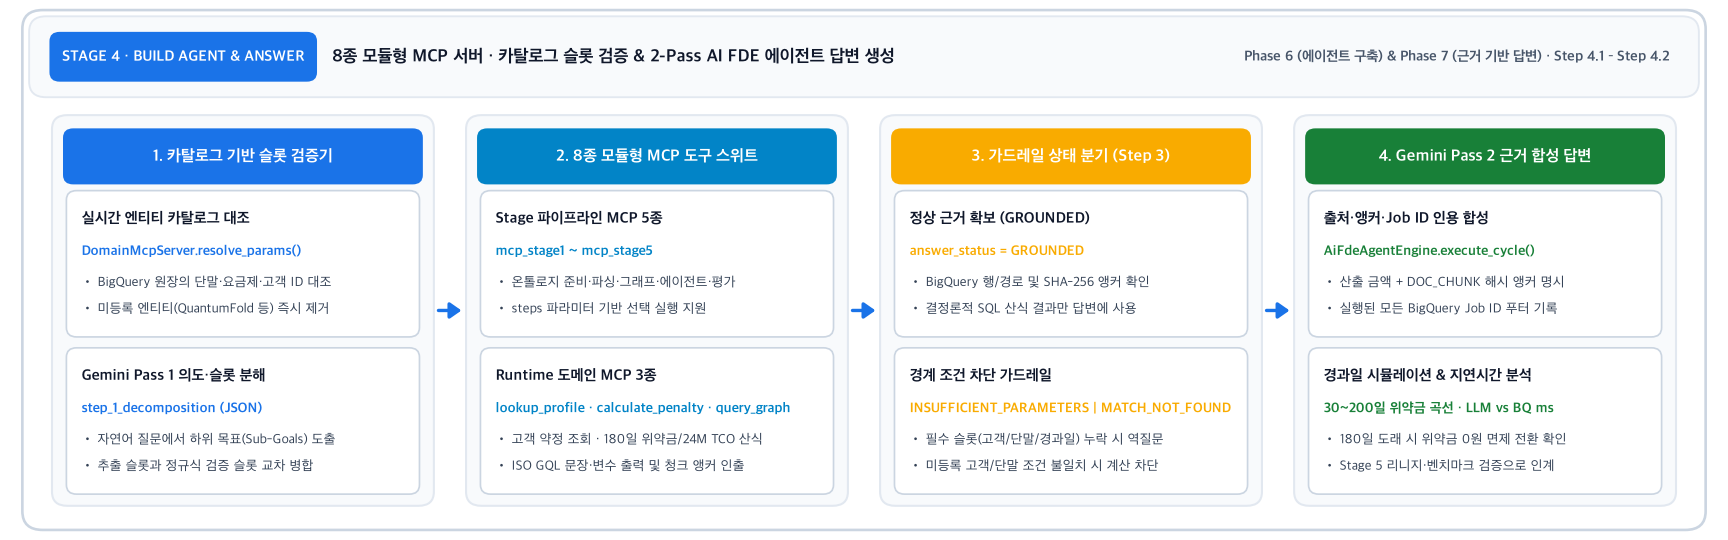


In [1]:
%load_ext bigframes
import sys
from pathlib import Path
for _p in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
    if (_p / "nb_helpers.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
from src.agent.reasoning_engine import AiFdeAgentEngine
H.setup("ko")
server = DomainMcpServer()
agent = AiFdeAgentEngine()


### 1. [Phase 6a: 에이전트 및 MCP 서버 아키텍처 구축] 2-Pass 오케스트레이션 설계도 · 8종 MCP 도구 카탈로그 · `mcp_stage4_agent_orchestration`


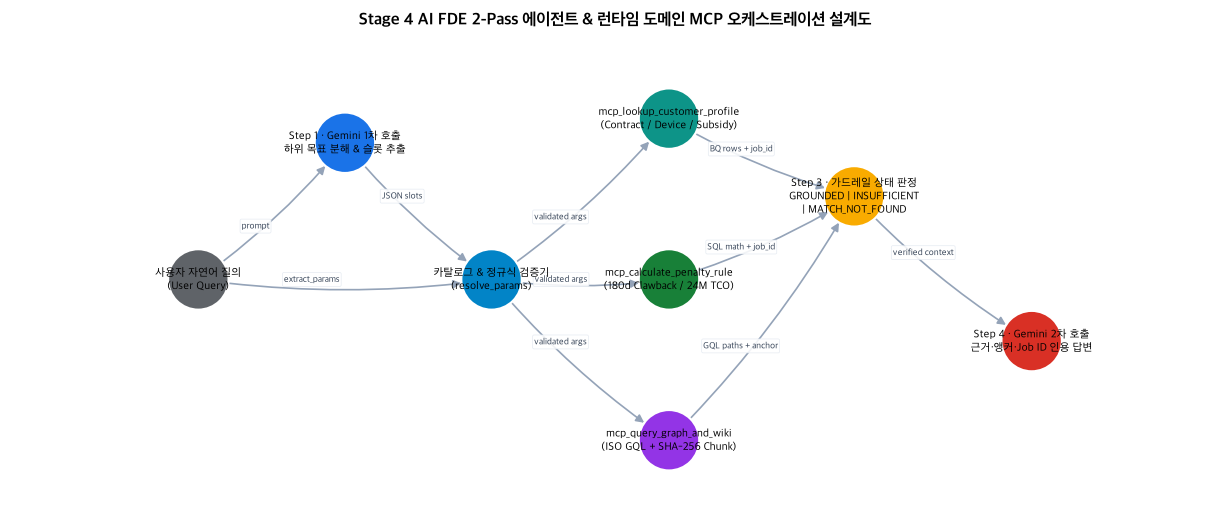

,name,stage,category,steps,spec_origin,description
0,mcp_stage1_asset_discovery,STAGE 1,stage_pipeline,"[profile_tables, scan_guides, prune_noise, tag_pii_governance]",GCP_NATIVE,Stage 1 BigQuery / Cloud Spanner 테이블 실측 프로파일링 및 고객 식별자 비식별화 규칙 검사
1,mcp_stage2_wiki_and_semantic,STAGE 2,stage_pipeline,"[compile_3layer_wiki, extract_hash_anchors, bind_semantic_bridges]",CUSTOM_EXTENSION,Stage 2 GCS 위키 객체 목록 및 BigQuery / Spanner 문서 청크·규칙 앵커 조회
2,mcp_stage3_property_graph,STAGE 3,stage_pipeline,"[promote_dw_nodes, synthesize_graph_ddl, verify_gql_templates]",GCP_NATIVE,Stage 3 노드 테이블 중복 키 검사 및 Property Graph (BigQuery / Spanner) GQL 경로 수 실측
3,mcp_stage4_agent_orchestration,STAGE 4,stage_pipeline,"[decompose_subgoals, dispatch_domain_mcps, verify_grounding_anchors]",CUSTOM_EXTENSION,Stage 4 에이전트가 사용하는 도메인 규칙과 근거 청크를 활성 엔진(BigQuery / Spanner)에서 조회
4,mcp_stage5_lineage_and_eval,STAGE 5,stage_pipeline,"[build_4tier_lineage, run_golden_cq_suite, diagnose_boundary_failures]",CUSTOM_EXTENSION,Stage 5 고객 약정→단말·요금제·지원금→규칙→청크 리니지 조인 및 최근 검증 리포트 요약
5,mcp_lookup_customer_profile,RUNTIME,runtime_domain,"[lookup_contract, lookup_device_price, lookup_subsidy_policy]",CUSTOM_EXTENSION,고객 약정·단말 출고가·요금제별 공시지원금/추가지원금/실구매가 조회 (BigQuery / Spanner 지원)
6,mcp_calculate_penalty_rule,RUNTIME,runtime_domain,"[check_exemptions, compute_180d_prorated_clawback, compare_24m_tco]",CUSTOM_EXTENSION,180일 차액정산 위약금·특례 면제·24개월 TCO를 BigQuery 또는 Cloud Spanner SQL로 계산
7,mcp_query_graph_and_wiki,RUNTIME,runtime_domain,"[traverse_property_graph, fetch_okf_hash_anchor, verify_dw_schema]",GCP_NATIVE,Property Graph GRAPH_TABLE 멀티홉 탐색(BigQuery / Spanner) 및 규칙 근거 청크 원문 조회


**`mcp_stage4_agent_orchestration`** · engine `bigquery` · status `SUCCESS` · steps `decompose_subgoals, dispatch_domain_mcps, verify_grounding_anchors` · jobs 1 (484.4 ms)

도메인 규칙 4개와 근거 청크 앵커 조회 (bigquery)

- `job_iaO7pzMNW9lKgn6bSXvbDg5sx1rs`

,rule_id,rule_name,rule_category,condition_expr,formula_expr,source_chunk_id,anchor
0,RULE_SIX_PLAN_180D,"180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙",PENALTY_180D,elapsed_days < 180 AND target_plan_monthly_fee < 45000,penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days...,DOC_CHUNK_003,anchor_47971ec8e4d8
1,RULE_SUBSIDY_CAP,공시지원금 및 유통망 추가지원금(15%) 합산 규칙,SUBSIDY_CAP,contract_type == 'PUBLIC_SUBSIDY',total_subsidy = base_subsidy_krw + additional_subsidy_cap_krw; net_principal = factory...,DOC_CHUNK_001,anchor_a52e1a72869f
2,RULE_TCO_24M,24개월 공시지원금 vs 25% 선택약정 총비용(TCO) 비교 규칙,TCO_24M,commitment_months == 24,subsidy_24m_tco = (factory_price_krw - total_subsidy) + (monthly_fee_krw * 24); select...,DOC_CHUNK_005,anchor_4fbaf9c5cba8
3,RULE_WELFARE_EXEMPT,시니어·복지 요금제 전환 및 군입대 장기정지 위약금 면제 특례,WELFARE_EXEMPT,"welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')",penalty = 0 (SENIOR_EXEMPT) OR pause_commitment_counter (MILITARY_PAUSE_ELIGIBLE),DOC_CHUNK_004,anchor_269d9c42e05c


In [2]:
H.draw_agent_architecture()
H.show(pd.DataFrame(server.get_tool_catalog()), ["name", "stage", "category", "steps", "spec_origin", "description" if H.LANG == "ko" else "description_en"])
res_s4 = server.execute_tool("mcp_stage4_agent_orchestration", {"steps": ["decompose_subgoals", "dispatch_domain_mcps", "verify_grounding_anchors"]})
H.show_tool(res_s4, "active_rules")


### 2. [Phase 6b: 카탈로그 기반 슬롯 파싱 검증 (`resolve_params`)] 자연어 질문에서 안전하게 파라미터를 추출하고 미등록 엔티티를 차단하는 과정


In [3]:
sample_queries = [
    "CUST_DEMO_001 고객이 개통 120일 시점에 5G Light(37,000원)로 하향 변경하면 위약금이 얼마인가요?",
    "AlphaPhone 16 Pro 256GB 단말기를 5G Signature 115 요금제로 개통할 때 지원금과 실구매가는?",
    "CUST_NOT_EXIST_999 고객이 QuantumFold 99 단말기로 99,000원 요금제 변경 시 위약금은?",
    "방금 개통했는데 37,000원 요금제로 내리면 위약금이 얼마인가요?",
]
slot_rows = []
for q in sample_queries:
    resolved = server.resolve_params({"query": q})
    slot_rows.append({"query": q, **{k: v for k, v in resolved.items()}})
H.show(pd.DataFrame(slot_rows))


,query,customer_id,device_name,storage_gb,plan_name,monthly_fee_krw,target_plan_name,target_monthly_fee_krw,elapsed_days
0,"CUST_DEMO_001 고객이 개통 120일 시점에 5G Light(37,000원)로 하향 변경하면 위약금이 얼마인가요?",CUST_DEMO_001,None,NaN,5G Light (Below Baseline),NaN,None,37000.0,120.0
1,AlphaPhone 16 Pro 256GB 단말기를 5G Signature 115 요금제로 개통할 때 지원금과 실구매가는?,NaN,None,256.0,NaN,NaN,None,NaN,NaN
2,"CUST_NOT_EXIST_999 고객이 QuantumFold 99 단말기로 99,000원 요금제 변경 시 위약금은?",NaN,None,NaN,NaN,99000.0,None,NaN,NaN
3,"방금 개통했는데 37,000원 요금제로 내리면 위약금이 얼마인가요?",NaN,None,NaN,NaN,37000.0,None,NaN,NaN


### 3. [Phase 6c: 런타임 도메인 MCP 3종 직접 호출 및 GQL 문장/변수 확인] 고객 프로필 · 위약금/24개월 TCO 산식 · 그래프/위키 탐색(`executed_gql`) 및 180일 위약금 곡선


**`mcp_lookup_customer_profile`** · engine `bigquery` · status `SUCCESS` · steps `lookup_contract, lookup_device_price, lookup_subsidy_policy` · jobs 1 (488.1 ms)

**1) GQL 바인딩 변수 명세 (Bound Variables & Parameters)**

| `바인딩 변수 / 슬롯` | `바인딩 값 (Bound Value)` | 타입 / 바인딩 위치 |
|:---|:---|:---|
| `customer_id` | `CUST_DEMO_001` | DomainMcpServer.resolve_params() 카탈로그 검증 슬롯 |

- `job_TX34_03jAwmks7yBnTohsDhTfIRN`

,customer_id,device_name,plan_name,monthly_fee_krw,factory_price_krw,total_subsidy_krw,net_installment_principal_krw,grounded_chunk_id
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,85000,1698400,517500,1180900,DOC_CHUNK_001


**`mcp_calculate_penalty_rule`** · engine `bigquery` · status `SUCCESS` · steps `check_exemptions, compute_180d_prorated_clawback, compare_24m_tco` · jobs 2 (1,020.8 ms)

**1) GQL 바인딩 변수 명세 (Bound Variables & Parameters)**

| `바인딩 변수 / 슬롯` | `바인딩 값 (Bound Value)` | 타입 / 바인딩 위치 |
|:---|:---|:---|
| `customer_id` | `CUST_DEMO_001` | DomainMcpServer.resolve_params() 카탈로그 검증 슬롯 |
| `target_monthly_fee_krw` | `37000` | DomainMcpServer.resolve_params() 카탈로그 검증 슬롯 |
| `elapsed_days` | `120` | DomainMcpServer.resolve_params() 카탈로그 검증 슬롯 |

- `job_7U7JJGDkVQcSRm8eECwfXz17ONII`
- `job_DQCr27l_i9FSpo0gDHMbtT8ol3CM`

,customer_id,plan_name,target_plan_name,elapsed_days,penalty_status,penalty_krw,public_subsidy_24m_tco_krw,selective_24m_tco_krw,tco_recommendation,grounded_chunk_id
0,CUST_DEMO_001,5G Premier Essential,5G Light (Below Baseline),120,PRORATED_PENALTY,100000,3220900,3228400,PUBLIC_SUBSIDY,DOC_CHUNK_003


**`mcp_query_graph_and_wiki`** · engine `bigquery` · status `SUCCESS` · steps `traverse_property_graph, fetch_okf_hash_anchor, verify_dw_schema` · jobs 1 (542.7 ms)

**1) GQL 바인딩 변수 명세 (Bound Variables & Parameters)**

| `바인딩 변수 / 슬롯` | `바인딩 값 (Bound Value)` | 타입 / 바인딩 위치 |
|:---|:---|:---|
| `customer_id` | `CUST_DEMO_001` | DomainMcpServer.resolve_params() 카탈로그 검증 슬롯 |

**실행된 GRAPH_TABLE / ISO GQL 문장 (Executed GQL Statement)**
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (c.customer_id AS customer_id, c.contract_id AS contract_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE g.customer_id = 'CUST_DEMO_001'
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- `job_S8e7PHS3-oggC4QvvuS7F8q1bFcY`

,customer_id,device_name,plan_name,rule_id,relation_label_ko,source_chunk_id,anchor
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,RULE_SIX_PLAN_180D,180일 기준선 유지 의무 적용,DOC_CHUNK_002,anchor_3003b683cea0
1,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,RULE_TCO_24M,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005,anchor_4fbaf9c5cba8


,elapsed_days,penalty_krw,penalty_status,applied_rule_id,public_24m_tco_krw,selective_24m_tco_krw,bq_job_id
0,30,250000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_krfu4al18vxpYU0CgKRyFCDN4V3l
1,60,200000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_Q1g6uxHH4kXmDfJcgfqBvETDfHCv
2,90,150000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_rMBihm0lzjiFlnzUJG5AmcguxtfQ
3,120,100000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_c8aU-P86_t-jfi3Zd1Kv3NtmH_sQ
4,150,50000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_sqFlPTAyu1y8p6A9ZvOySX5OjkV2
5,179,1667,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_yssydP7WTceYiFp89cSfpymJV-hf
6,180,0,EXEMPT_RETENTION_COMPLETED,RULE_SIX_PLAN_180D,3220900,3228400,job_58KYz9e5vl-9XiCZlCM91ofcCN1l
7,200,0,EXEMPT_RETENTION_COMPLETED,RULE_SIX_PLAN_180D,3220900,3228400,job_tL0EzkuY0grLt-bK5y7uDLVWID0w


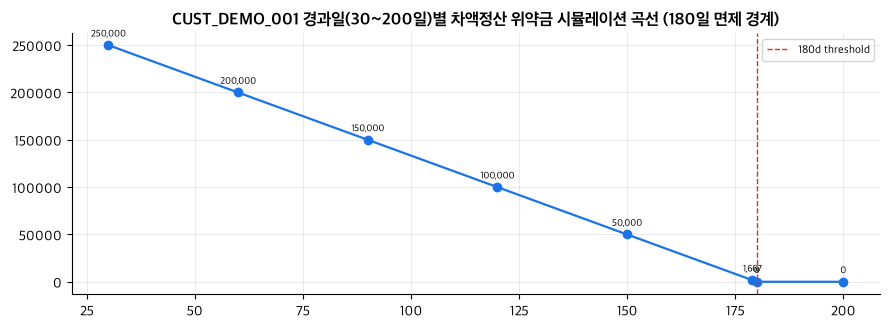

In [4]:
r_prof = server.execute_tool("mcp_lookup_customer_profile", {"customer_id": "CUST_DEMO_001"})
H.show_tool(r_prof, "matched_rows", ["customer_id", "device_name", "plan_name", "monthly_fee_krw", "factory_price_krw", "total_subsidy_krw", "net_installment_principal_krw", "grounded_chunk_id"])

r_pen = server.execute_tool("mcp_calculate_penalty_rule", {"customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120})
H.show_tool(r_pen, "calculations", ["customer_id", "plan_name", "target_plan_name", "elapsed_days", "penalty_status", "penalty_krw", "public_subsidy_24m_tco_krw", "selective_24m_tco_krw", "tco_recommendation", "grounded_chunk_id"])

r_gql = server.execute_tool("mcp_query_graph_and_wiki", {"customer_id": "CUST_DEMO_001"})
H.show_tool(r_gql, "matched_graph_paths", ["customer_id", "device_name", "plan_name", "rule_id", "relation_label_ko", "source_chunk_id", "anchor"])

df_curve = H.penalty_curve(server, "CUST_DEMO_001", 37000, [30, 60, 90, 120, 150, 179, 180, 200])
H.show(df_curve)
H.line(df_curve, "elapsed_days", "penalty_krw",
       "CUST_DEMO_001 경과일(30~200일)별 차액정산 위약금 시뮬레이션 곡선 (180일 면제 경계)",
       vline=180, vline_label="180d threshold")


### 4. [Phase 6d: 양대 그래프 엔진 MCP 런타임 비교 (`engine="bigquery"` vs `engine="spanner"`)] Cloud Spanner Graph 직접 실행 및 결과 정합성·지연시간 대조


**`mcp_query_graph_and_wiki`** · engine `spanner` · status `SUCCESS` · steps `traverse_property_graph, fetch_okf_hash_anchor, verify_dw_schema` · jobs 1 (186.8 ms)

**1) GQL 바인딩 변수 명세 (Bound Variables & Parameters)**

| `바인딩 변수 / 슬롯` | `바인딩 값 (Bound Value)` | 타입 / 바인딩 위치 |
|:---|:---|:---|
| `customer_id` | `CUST_DEMO_001` | DomainMcpServer.resolve_params() 카탈로그 검증 슬롯 |

**실행된 GRAPH_TABLE / ISO GQL 문장 (Executed GQL Statement)**
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`STARTER_ONTOLOGY_GRAPH`
  MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (c.customer_id AS customer_id, c.contract_id AS contract_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE g.customer_id = 'CUST_DEMO_001'
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- `spanner:starter-spanner/starter_ontology_db@1790745420710`

,customer_id,device_name,plan_name,rule_id,relation_label_ko,source_chunk_id,anchor
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,RULE_SIX_PLAN_180D,180일 기준선 유지 의무 적용,DOC_CHUNK_002,anchor_3003b683cea0
1,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,RULE_TCO_24M,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005,anchor_4fbaf9c5cba8


,mcp_tool,bigquery_status,spanner_status,bigquery_ms,spanner_ms,bq_rows,spanner_rows,result_parity
0,mcp_lookup_customer_profile,SUCCESS,SUCCESS,450.67,947.47,1,1,True
1,mcp_calculate_penalty_rule,SUCCESS,SUCCESS,964.68,428.81,1,1,True
2,mcp_query_graph_and_wiki,SUCCESS,SUCCESS,487.31,186.76,2,2,True


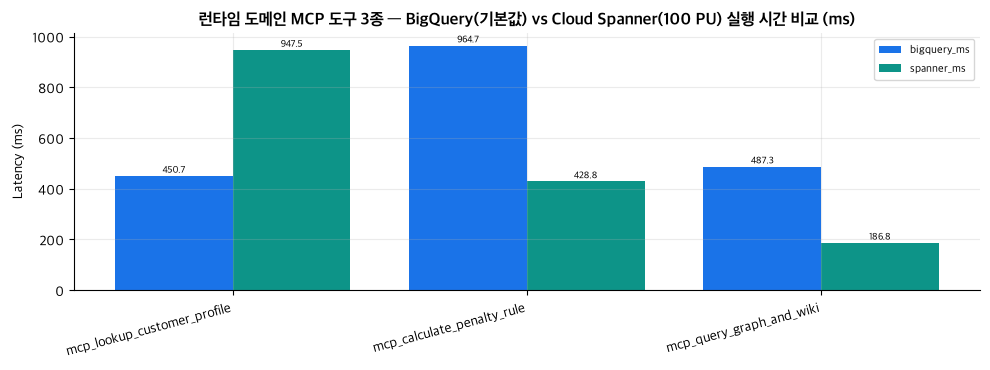

In [5]:
df_mcp_eng = H.compare_mcp_engines(server)
H.show(df_mcp_eng)
H.grouped_bar(df_mcp_eng, "mcp_tool", ["bigquery_ms", "spanner_ms"],
              "런타임 도메인 MCP 도구 3종 — BigQuery(기본값) vs Cloud Spanner(100 PU) 실행 시간 비교 (ms)",
              fmt="{:,.1f}", ylabel="Latency (ms)")


### 5. [Phase 7: 2-Pass 에이전트 End-to-End 답변 생성] Golden CQ(`GROUNDED`) 및 경계 조건(`INSUFFICIENT_PARAMETERS`, `MATCH_NOT_FOUND`) 4단계 트레이스


#### CQ-01 (Subsidy & Net Price)
**Q.** AlphaPhone 16 Pro 256GB 단말기를 5G Signature 115 요금제로 개통할 때 공시지원금, 유통망 추가지원금 상한, 총 지원금과 실구매가는 얼마인가요?

- **Step 1 (의도 분해 & 파라미터 추출)**: sub-goals - · params `{"storage_gb": 256, "device_mention": "AlphaPhone 16 Pro 256GB", "plan_mention": "5G Signature 115"}`
- **Step 2 (MCP 도구 체이닝 실행)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 5 | 597 | `job_eW2d6tyH1ZffCdQ7fZss2OspRZdn` |
| 2 | `mcp_query_graph_and_wiki` | `SUCCESS` | 10 | 732 | `job_v8EMoxGxaguo97Ttt-X6wyj2-48P` |

- **`mcp_query_graph_and_wiki` 실행 GQL 문장 및 바인딩 변수** (`params={"storage_gb": 256, "device_mention": "AlphaPhone 16 Pro 256GB", "plan_mention": "5G Signature 115"}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (d:DeviceNode)-[hs:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (hs.policy_id AS policy_id, hs.total_subsidy_krw AS total_subsidy_krw, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE TRUE
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (근거 앵커 및 가드레일 판정)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 7,970 tokens, LLM 21,425 ms / total 23.2 s)

- **Step 4 (근거 인용 에이전트 최종 답변)**:

> ### 결론
>
> 요청 조건인 **AlphaPhone 16 Pro 256GB** 단말기 및 **5G Signature 115** 요금제와 일치하는 데이터가 BigQuery(`seanjung-poc.starter_ontology_dw`)에 존재하지 않아(0건), 해당 단말기 및 요금제의 공시지원금, 유통망 추가지원금 상한, 총 지원금, 실구매가를 산출할 수 없습니다.
>
> 현재 저장소에는 저장용량 256GB 조건과 관련하여 **iPhone 16 Pro 256GB** 및 **Galaxy S26 Ultra 256GB** 단말기에 대한 정책 데이터만 존재합니다.
>
> ---
>
> ### 근거 데이터 (BigQuery)
>
> 참고(질문과 다른 조건)로 저장소에 존재하는 256GB 단말 정책 데이터는 다음과 같습니다:
>
> 1. **iPhone 16 Pro 256GB (`DEV-IP16P-256`) / 5G Premier Essential (`PLAN-5G-85`, 월 85,000원)**
>    - 출고가: 1,700,000원
>    - 공시

#### CQ-02 (120d Prorated Penalty)
**Q.** CUST_DEMO_001 고객이 개통 후 120일 시점에 월 37,000원 요금제(5G Lite 37)로 하향 변경하면 차액정산 위약금은 얼마인가요?

- **Step 1 (의도 분해 & 파라미터 추출)**: sub-goals - · params `{"target_plan_name": "5G Light (Below Baseline)", "customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120, "target_plan_mention": "5G Lite 37"}`
- **Step 2 (MCP 도구 체이닝 실행)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 548 | `job_9S2fm5YAtsiCiIoVI1jpZBOtNb_p` |
| 2 | `mcp_calculate_penalty_rule` | `SUCCESS` | 1 | 1,055 | `job_iWHgv-eqHQVTillawBGMn1apIqEB`, `job__o6OOiEdqSOXKLnb79gzK3NDEXsU` |
| 3 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 547 | `job_BwxoKti5qjT0P_jd2tgEaEznHKrR` |

- **`mcp_query_graph_and_wiki` 실행 GQL 문장 및 바인딩 변수** (`params={"target_plan_name": "5G Light (Below Baseline)", "customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120, "target_plan_mention": "5G Lite 37"}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (c.customer_id AS customer_id, c.contract_id AS contract_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE g.customer_id = 'CUST_DEMO_001'
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (근거 앵커 및 가드레일 판정)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 6,745 tokens, LLM 13,155 ms / total 15.31 s)

- **Step 4 (근거 인용 에이전트 최종 답변)**:

> ### **결론**
> CUST_DEMO_001 고객이 개통 후 120일 시점에 월 37,000원 요금제(5G Light (Below Baseline))로 하향 변경할 경우 발생하는 차액정산 위약금은 **100,000원**입니다.
>
> ---
>
> ### **근거 데이터 (BigQuery)**
>
> * **고객 및 계약 정보**
>   * 고객 ID: `CUST_DEMO_001` (계약 ID: `CONTRACT_DEMO_101`)
>   * 약정 유형: `PUBLIC_SUBSIDY` (공시지원금 개통)
>   * 단말기: `Galaxy S26 Ultra 256GB` (출고가: 1,698,400원)
>   * 복지 감면 대상 여부: `NONE`
>   * 경과 일수: `120일` (의무유지 기준일: 180일)
>
> * **요금제 및 지원금 정보**
>   * **현재 요금제**: `5G Premier Essential` (월 85,000원)
>     * 기본 공시지원금: 450,000원
>     * 추가지원금: 67,500원 (총 지원금 517,500원)
>   * **변경 대상 요금제**: `5G Light (Below Baseline)` (월 37,000원)
>     * 기준선(45,000원) 미만 요금제
>     * 변경 대상 기본 공시지원금: 150,000원
>
> * **위약금 산식 및 계산**
>   * **산식**: `(초기 기본지원금 - 하향요금제 기본지원금) × (180 - 경과일수) / 180`
>   * **계산**: $(450,000\text{원} - 150,000\text{원}) \times \frac{180 - 120}{180} = 300,000\text{원} \times \frac{60}{180} = \mathbf{100,000\text{원}}$
>   * **위약금 부과 상태**: `PRORATED_PENALTY`
>
> ---
>
> ### **규칙·원문 근거**
>
> * **적용 규칙 ID**: `RULE_SIX_PLAN_180D` (180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙)
>   * **조건식**: `elapsed_days < 180 AND target_plan_monthly_fee < 45000`
>   * **산식 식**: `penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days) / 180)`
>   * **관련 청크 ID**: 
>     * `DOC_CHUNK_003` (위약금 일할 계산 및 규칙)
>     * `DOC_CHUNK_002` (Baseline Plan Commitment (Six-Plan Rule))
>
> ---
>
> ### **실행 정보**
> * **BigQuery Job ID**:
>   * 고객 프로필 조회: `job_9S2fm5YAtsiCiIoVI1jpZBOtNb_p`
>   * 위약금 산정: `job__o6OOiEdqSOXKLnb79gzK3NDEXsU` (선행 조회: `job_iWHgv-eqHQVTillawBGMn1apIqEB`)
>   * 온톨로지 그래프/규칙 검색: `job_BwxoKti5qjT0P_jd2tgEaEznHKrR`

#### CQ-03 (Welfare Exemption)
**Q.** 국가유공자 복지감면 등록 고객인 CUST_DEMO_002가 개통 95일 만에 하위 요금제로 변경할 때 위약금이 면제되나요?

- **Step 1 (의도 분해 & 파라미터 추출)**: sub-goals - · params `{"customer_id": "CUST_DEMO_002", "elapsed_days": 95, "target_plan_mention": "하위 요금제"}`
- **Step 2 (MCP 도구 체이닝 실행)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 559 | `job_EfLfQfFJMxYFq9L5Z9vzHYOsLm8p` |
| 2 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 582 | `job_0Hiexr2IgwHN1dYtD9UUv6ftuVjC` |
| 3 | `mcp_calculate_penalty_rule` | `SUCCESS` | 1 | 1,123 | `job_x04YJPpIcmSDabLsK9nhg5_s-CNh`, `job_qtszj_TfUBugeoEDiFSfzTDSF5lp` |

- **`mcp_query_graph_and_wiki` 실행 GQL 문장 및 바인딩 변수** (`params={"customer_id": "CUST_DEMO_002", "elapsed_days": 95, "target_plan_mention": "하위 요금제"}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (c:CustomerContractNode)-[:USES_DEVICE]->(d:DeviceNode), (c)-[:SUBSCRIBES_PLAN]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (c.customer_id AS customer_id, c.contract_id AS contract_id, c.welfare_status AS welfare_status, c.elapsed_days AS elapsed_days, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE g.customer_id = 'CUST_DEMO_002'
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (근거 앵커 및 가드레일 판정)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 6,670 tokens, LLM 14,547 ms / total 16.81 s)

- **Step 4 (근거 인용 에이전트 최종 답변)**:

> ### **결론**
> **위약금은 면제되지 않습니다.**
>
> 고객(`CUST_DEMO_002`)의 원장상 복지 감면 자격(`welfare_status`)은 **`NONE`**(일반 고객)으로 등록되어 있어 복지 특례 면제 대상(`SENIOR_EXEMPT`)에 해당하지 않습니다. 또한 공시지원금 약정(`PUBLIC_SUBSIDY`) 상태에서 의무 유지 기간(180일) 이전인 **95일** 시점에 기준선(월 45,000원) 미만의 요금제로 하향 변경할 경우 차액위약금이 부과됩니다.
>
> ---
>
> ### **근거 데이터 (BigQuery)**
>
> - **고객 계약 정보 (`CUST_DEMO_002` / `CONTRACT_DEMO_102`)**
>   - **고객 세그먼트**: `General_Standard` (연령대: `30s-40s`)
>   - **복지 자격 상태 (`welfare_status`)**: `NONE` (국가유공자 복지감면 등록 내역 없음)
>   - **약정 유형**: `PUBLIC_SUBSIDY` (공시지원금 약정, 약정기간 24개월)
>   - **현재 요금제**: `5G Premier Super` (월 130,000원)
>   - **기본 지원금 (`base_subsidy_krw`)**: 500,000원 (추가지원금 75,000원, 총 지원금 575,000원)
>   - **기준선 요금 (`baseline_fee_krw`)**: 45,000원
>   - **의무 유지 일수**: 180일 (요청 변경 시점: 95일)
>
> ---
>
> ### **규칙·원문 근거**
>
> 1. **복지 면제 특례 규칙 (`RULE_WELFARE_EXEMPT`)** [청크 ID: `DOC_CHUNK_004`]
>    - **적용 조건**: `welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')`
>    - 만 65세 이상 시니어 복지 특례(`SENIOR_EXEMPT`) 대상자 등에 한해 위약금 면제가 적용되나, 본 고객의 상태는 `NONE`이므로 면제 특례가 적용되지 않습니다.
>
> 2. **180일 기준선 의무유지 및 일할 차액위약금 규칙 (`RULE_SIX_PLAN_180D`)** [청크 ID: `DOC_CHUNK_002`, `DOC_CHUNK_003`]
>    - **적용 조건**: `elapsed_days < 180 AND target_plan_monthly_fee < 45000`
>    - **위약금 산식**:
>      $$\text{위약금} = \text{ROUND}\left((\text{기존 기본지원금} - \text{변경 요금제 기본지원금}) \times \frac{180 - \text{유지일수}}{180}\right)$$
>    - 변경하려는 하위 요금제가 월 45,000원 미만 요금제일 경우, 잔여일수(180일 - 95일 = 85일)에 대한 일할 차액위약금이 발생합니다. *(※ 목표 요금제가 특정되지 않아 정확한 위약금 수치는 미산정)*
>
> ---
>
> ### **실행 정보**
> - **프로필 조회 Job ID**: `job_EfLfQfFJMxYFq9L5Z9vzHYOsLm8p`
> - **그래프 및 온톨로지 조회 Job ID**: `job_0Hiexr2IgwHN1dYtD9UUv6ftuVjC`
> - **위약금 연산 Job ID**: `job_qtszj_TfUBugeoEDiFSfzTDSF5lp`

#### BC-PARAM (Missing Customer/Device)
**Q.** 방금 개통한 고객인데 지금 5G Lite 37 요금제로 내리면 위약금이 얼마인가요?

- **Step 1 (의도 분해 & 파라미터 추출)**: sub-goals - · params `{}`
- **Step 2 (MCP 도구 체이닝 실행)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_query_graph_and_wiki` | `SUCCESS` | 10 | 633 | `job_kS1Pp4lc5Uk0Wh0GFxZ1q0Y9JUsL` |

- **`mcp_query_graph_and_wiki` 실행 GQL 문장 및 바인딩 변수** (`params={}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (d:DeviceNode)-[hs:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (hs.policy_id AS policy_id, hs.total_subsidy_krw AS total_subsidy_krw, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE TRUE
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (근거 앵커 및 가드레일 판정)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 6,303 tokens, LLM 23,832 ms / total 24.47 s)

- **Step 4 (근거 인용 에이전트 최종 답변)**:

> ### **결론**
> 개통 직후(사용일수 0일) 5G 기준선(월 45,000원) 미만 요금제인 **5G Light (Below Baseline, 월 37,000원)**로 변경할 경우, 의무유지 기간(180일) 미충족으로 인해 **공시지원금 차액정산금(위약금)**이 전액 일할 부과됩니다. 
>
> 위약금 산식에 따라 개통 시 지원받은 공시지원금과 5G Light 지원금의 차액이 전액 청구되며, **Galaxy S26 Ultra 256GB** 기준 개통 요금제에 따른 위약금은 다음과 같습니다:
> - **5G Premier Super (월 130,000원) 개통 고객**: **402,500원**
> - **5G Premier Essential (월 85,000원) 개통 고객**: **345,000원**
> - **5G Slim (월 45,000원) 개통 고객**: **172,500원**
>
> ---
>
> ### **근거 데이터 (BigQuery)**
>
> #### 1. 위약금 산식
> - **산식**: `Penalty = (Initial Granted Subsidy - Lower Tier Subsidy) * (180 - Elapsed Days) / 180`
> - **방금 개통(사용일수 = 0일) 적용 시**: `(개통 시 지원금 - 172,500원) * 180 / 180`
>
> #### 2. 요금제별

#### BC-NOTFOUND (Unknown Entity)
**Q.** CUST_NOT_EXIST_999 고객이 QuantumFold 99 단말기로 요금제를 변경할 때 위약금을 계산해 주세요.

- **Step 1 (의도 분해 & 파라미터 추출)**: sub-goals - · params `{"device_mention": "QuantumFold 99"}`
- **Step 2 (MCP 도구 체이닝 실행)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 7 | 594 | `job_0ysJ3xlWS8SmqzWO6iqnhtEWpWy8` |
| 2 | `mcp_calculate_penalty_rule` | `INSUFFICIENT_PARAMETERS` | - | 504 | `job_ciPshv0MAt4tp8aPKEHA3wZyoL2_` |
| 3 | `mcp_query_graph_and_wiki` | `SUCCESS` | 10 | 535 | `job_yXg10UcNpPAj8oiZhBSJdYSAk-b4` |

- **`mcp_query_graph_and_wiki` 실행 GQL 문장 및 바인딩 변수** (`params={"device_mention": "QuantumFold 99"}`):
```sql
SELECT g.*, ch.section_title, ch.content_sha256 AS anchor, ch.content AS chunk_text
FROM GRAPH_TABLE(`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`
  MATCH (d:DeviceNode)-[hs:HAS_SUBSIDY_POLICY]->(p:PlanNode)<-[ap:APPLIES_TO_PLAN]-(r:DomainRuleNode)
  COLUMNS (hs.policy_id AS policy_id, hs.total_subsidy_krw AS total_subsidy_krw, d.device_name AS device_name, d.factory_price_krw AS factory_price_krw,
           p.plan_name AS plan_name, p.monthly_fee_krw AS monthly_fee_krw,
           r.rule_id AS rule_id, r.rule_name AS rule_name,
           ap.relation_label_ko AS relation_label_ko, ap.source_chunk_id AS source_chunk_id)) g
LEFT JOIN `seanjung-poc.starter_ontology_dw.tb_doc_chunks` ch ON ch.chunk_id = g.source_chunk_id
WHERE TRUE
ORDER BY g.device_name, g.monthly_fee_krw DESC, g.rule_id
```

- **Step 3 (근거 앵커 및 가드레일 판정)**: `answer_status=INSUFFICIENT_PARAMETERS` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 10,553 tokens, LLM 14,516 ms / total 16.16 s)

- **Step 4 (근거 인용 에이전트 최종 답변)**:

> ### **결론**
> 요청하신 고객(`CUST_NOT_EXIST_999`) 및 단말기(`QuantumFold 99`)에 해당하는 계약 정보가 BigQuery 온톨로지 데이터에 존재하지 않으며, 필수 파라미터가 누락되어 위약금을 계산할 수 없습니다.
>
> 계산 수행을 위해 아래 파라미터가 추가로 필요합니다:
> - **누락된 정보(missing_slots)**:
>   1. `customer_id` 또는 단말기(+가입 요금제)
>   2. `개통 후 경과일수` (elapsed_days)
>   3. `변경 희망 요금제` (target_plan_name)
>
> ---
>
> ### **근거 데이터 (BigQuery)**
>
> 현재 데이터베이스(`seanjung-poc.starter_ontology_dw`)에 등록된 단말기 및 요금제 조건은 다음과 같습니다:
>
> 1. **단말기 및 출고가 현황**
>    - Galaxy S26 Ultra 256GB (`DEV-S26U-256`): 1,698,400원
>    - Galaxy S26 Ultra 512GB (`DEV-S26U-512`): 1,841,400원
>    - iPhone 16 Pro 256GB (`DEV-IP16P-256`): 1,700,000원
>    - iPhone 16 Pro 512GB (`DEV-IP16P-512`): 2,000,000원
>
> 2. **지원금 및 요금제 정책 예시 (Galaxy S26 Ultra 256GB 기준)**
>    - **5G Premier Super** (월 130,000원): 기본지원금 500,000원 + 추가지원금 75,000원 = 총 575,000원 (실구매가 1,123,400원)
>    - **5G Premier Essential** (월 85,000원): 기본지원금 450,000원 + 추가지원금 67,500원 = 총 517,500원 (실구매가 1,180,900원)
>    - **5G Slim (Baseline Threshold)** (월 45,000원): 기본지원금 300,000원 + 추가지원금 45,000원 = 총 345,000원 (실구매가 1,353,400원)
>    - **5G Light (Below Baseline)** (월 37,000원): 기본지원금 150,000원 + 추가지원금 22,500원 = 총 172,500원 (실구매가 1,525,900원)
>
> ---
>
> ### **규칙·원문 근거**
>
> 위약금 및 계약 변경 산정 시 적용되는 도메인 규칙은 다음과 같습니다:
>
> - **RULE_SIX_PLAN_180D** (청크 ID: `DOC_CHUNK_002`, `DOC_CHUNK_003` / 앵커: `anchor_3003b683cea0`, `anchor_47971ec8e4d8`):
>   - **조건**: `elapsed_days < 180 AND target_plan_monthly_fee < 45000`
>   - **산식**: `penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days) / 180)`
>   - **설명**: 개통 후 180일 이내에 월정액 45,000원 미만 요금제로 하향 변경 시, 기본 공시지원금 차액에 잔여일수 비율을 곱한 일할 차액정산금이 부과됩니다. 180일 경과 시 위약금은 0원입니다.
> - **RULE_SUBSIDY_CAP** (청크 ID: `DOC_CHUNK_001` / 앵커: `anchor_a52e1a72869f`):
>   - 유통망 추가지원금은 기본 공시지원금의 최대 15%까지 지급되며, 실구매가는 출고가에서 총 지원금을 차감하여 계산합니다.
> - **RULE_WELFARE_EXEMPT** (청크 ID: `DOC_CHUNK_004` / 앵커: `anchor_269d9c42e05c`):
>   - 만 65세 이상 시니어 특례 대상자가 시니어/복지 요금제로 전환 시 180일 이내라도 위약금이 100% 면제(0원)됩니다.
> - **RULE_TCO_24M** (청크 ID: `DOC_CHUNK_005` / 앵커: `anchor_4fbaf9c5cba8`):
>   - 24개월 총소유비용(공시지원금 vs 선택약정 25% 요금할인)을 비교 산출하는 기준을 정의합니다.
>
> ---
>
> ### **실행 정보**
> - `mcp_lookup_customer_profile` BigQuery Job ID: `job_0ysJ3xlWS8SmqzWO6iqnhtEWpWy8`
> - `mcp_calculate_penalty_rule` BigQuery Job ID: `job_ciPshv0MAt4tp8aPKEHA3wZyoL2_`
> - `mcp_query_graph_and_wiki` BigQuery Job ID: `job_yXg10UcNpPAj8oiZhBSJdYSAk-b4`

,id,answer_status,tools,bq_jobs,tokens,llm_ms,bq_ms,total_s
0,CQ-01,GROUNDED,lookup_customer_profile > query_graph_and_wiki,3,7970,21425,1329,23.20
1,CQ-02,GROUNDED,lookup_customer_profile > calculate_penalty_rule > query_graph_and_wiki,5,6745,13155,2150,15.31
2,CQ-03,GROUNDED,lookup_customer_profile > query_graph_and_wiki > calculate_penalty_rule,5,6670,14547,2264,16.81
3,BC-PARAM,GROUNDED,query_graph_and_wiki,2,6303,23832,633,24.47
4,BC-NOTFOUND,INSUFFICIENT_PARAMETERS,lookup_customer_profile > calculate_penalty_rule > query_graph_and_wiki,4,10553,14516,1633,16.16


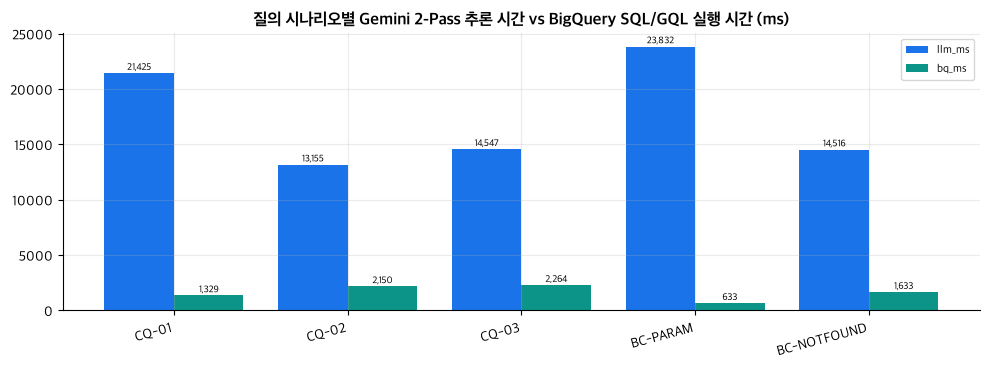

In [6]:
prompts = [
    ("CQ-01 (Subsidy & Net Price)", "AlphaPhone 16 Pro 256GB 단말기를 5G Signature 115 요금제로 개통할 때 공시지원금, 유통망 추가지원금 상한, 총 지원금과 실구매가는 얼마인가요?"),
    ("CQ-02 (120d Prorated Penalty)", "CUST_DEMO_001 고객이 개통 후 120일 시점에 월 37,000원 요금제(5G Lite 37)로 하향 변경하면 차액정산 위약금은 얼마인가요?"),
    ("CQ-03 (Welfare Exemption)", "국가유공자 복지감면 등록 고객인 CUST_DEMO_002가 개통 95일 만에 하위 요금제로 변경할 때 위약금이 면제되나요?"),
    ("BC-PARAM (Missing Customer/Device)", "방금 개통한 고객인데 지금 5G Lite 37 요금제로 내리면 위약금이 얼마인가요?"),
    ("BC-NOTFOUND (Unknown Entity)", "CUST_NOT_EXIST_999 고객이 QuantumFold 99 단말기로 요금제를 변경할 때 위약금을 계산해 주세요."),
]
runs = []
for qid, q in prompts:
    res = agent.execute_cycle(q)
    H.show_agent(res, title=qid)
    runs.append(H.agent_row(res, qid.split()[0]))
df_runs = pd.DataFrame(runs)
H.show(df_runs)
H.grouped_bar(df_runs, "id", ["llm_ms", "bq_ms"],
              "질의 시나리오별 Gemini 2-Pass 추론 시간 vs BigQuery SQL/GQL 실행 시간 (ms)")


### Q&A
- **Q.** AI FDE 에이전트는 위약금 계산 오류나 미등록 단말기/고객 환각을 어떻게 방지하며, 양대 그래프 엔진(`bigquery` / `spanner`)을 어떻게 전환하나요?
  - **A.** `resolve_params()`가 실시간 카탈로그(`get_live_catalog()`)와 대조하여 미등록 단말·요금제·고객 ID를 즉시 필터링하고, 모든 금액 계산과 그래프 탐색은 8종 MCP 도구에서 `engine='bigquery'`(기본값) 또는 `engine='spanner'`를 지정해 결정론적 SQL/GQL로만 수행하며, 필수 정보 누락 시 `INSUFFICIENT_PARAMETERS`, 조건 불일치 시 `MATCH_NOT_FOUND` 상태를 반환합니다.

### Data Analysis Key Findings
- `CUST_DEMO_001` 경과일 시뮬레이션(30~200일) 결과, 위약금은 30일차 `250,000원`에서 120일차 `100,000원`, 179일차 `1,667원`으로 선형 감소하며 180일 도래 즉시 `0원`(`EXEMPT_RETENTION_COMPLETED`)으로 전환됩니다.
- 런타임 도메인 MCP 3종(`mcp_lookup_customer_profile`, `mcp_calculate_penalty_rule`, `mcp_query_graph_and_wiki`)을 `engine='bigquery'`(기본값)와 `engine='spanner'`(`100 PU`) 양쪽에서 실행한 결과 동일한 반환 행 수(`result_parity=True`)와 SHA-256 앵커 정합성을 확인했습니다.
- Golden CQ(`CQ-01`~`CQ-03`)는 모두 `GROUNDED` 상태와 함께 정확한 금액(`575,000원`, `100,000원`, `0원`) 및 SHA-256 청크 앵커·BigQuery Job ID를 인용하여 답변했고, `BC-PARAM`과 `BC-NOTFOUND`는 수치 환각 없이 차단되었습니다.

### Insights or Next Steps
- 마지막 단계인 `Stage 5 (리니지·검증)` 노트북으로 이동하여 원천 파일부터 CQ 답변까지의 4-Tier 데이터 리니지 그래프와 Golden CQ 5종 / Boundary 50회 반복 벤치마크 배포 게이트를 검증하세요.

---
> **다음 학습 이동 (Navigation)**: [⬅️ Stage 3 · 그래프 구축](./stage3_property_graph_bigquery_spanner_ko.ipynb) ｜ [🏠 0. 전체 흐름 초기 화면](./stage0_overview_walkthrough_ko.ipynb) ｜ [➡️ Stage 5 · 리니지·검증](./stage5_lineage_and_evaluation_ko.ipynb) ｜ [🌐 English Version](../en/stage4_agent_and_mcp_execution_en.ipynb) ｜ [📖 방법론 문서](../../methodology/ko/04_stage4_agent_and_mcp_ko.md)
